# Amplitude-to-noise ratio

author: laquitainesteeve@gmail.com

Purpose: describe trace amplitude-to-noise ratio
 
Execution time: 2 min

Special hardware: on CPU, does not require GPU.

## Setup

1. Create, activate and select virtual environment kernel `demo` from (envs/demo.yml):

```bash
python -m ipykernel install --user --name demo --display-name "demo" # create kernel
```

2. Run pipeline in src/pipes/validation/anr/anr.py

In [1]:
%load_ext autoreload
%autoreload 2

import os
import numpy as np
import warnings
import pandas as pd
from matplotlib import pyplot as plt;

# import packages
import spikeinterface as si
from IPython.display import SVG, display
warnings.simplefilter(action='ignore', category=FutureWarning)

print("spikeinterface version:", si.__version__)

# move to repository path
proj_path = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(proj_path)

# setup colors
COLOR_NV = np.array([153, 153, 153]) / 255  # light gray
COLOR_NS = [0.9, 0.14, 0.15]  # red
COLOR_HV = [0.2, 0.2, 0.2]  # dark gray
COLOR_HS = np.array([26, 152, 80]) / 255  # green
COLOR_NB = [0.22, 0.5, 0.72]  # blue
COLOR_NE = [1, 0.49, 0]  # orange
pm = {"linestyle": "-", "linewidth": 1, "marker": "None"}


spikeinterface version: 0.100.8


In [2]:
# Nature figure guidelines for every saved figure: Arial, 5-7 pt, editable text, images of at least 300 dpi, a .pdf next to each .svg
import os, sys
sys.path.insert(0, os.getcwd())     # the repository (the notebook moved there above)
from src.nodes import figure_style
figure_style.apply()

## Custom functions

In [3]:
def plot_anr(ax, x, mean, ci, color, pm: dict):

    # plot mean
    ax.plot(x, mean, color=color, **pm)

    # plot confidence interval
    ax.fill_between(
        x,
        (mean),
        (mean + ci),
        color=color,
        linewidth=0.1,
        alpha=0.4,
        rasterized=True,
    )
    return ax

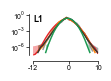

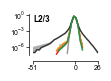

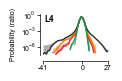

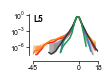

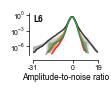

In [4]:
# Fig. 2q: one panel per layer, drawn from the source data with the geometry of panel q in paper/figures/fig2.pdf
from src.nodes.validation import anr_plots

for layer in ["l1", "l23", "l4", "l5", "l6"]:
    fig = anr_plots.plot_layer(layer, ylabel=(layer == "l4"), xlabel=(layer == "l6"))
    fig.savefig(f"figures/8_source_data/fig2q/fig2q_{layer}.svg", transparent=True, dpi=300)    # also saves the .pdf (figure_style)